# Two-group PPI: striatum–auditory cortex coupling by learning stage

ROI-to-ROI generalized PPI (`ppi_roi.py`): does coupling between the anterior caudate and auditory cortex depend on the task event, does it differ between learners (non-Mandarin, n = 12) and natives (Mandarin, n = 13), and does it change with learning?

**Model** (per participant × stage × seed; details in the `ppi_roi.py` docstring): the univariate `scrubbed-splitfb` design (sound, resp, fb_correct, fb_wrong, fb_noresp, drift, motion + aCompCor, FD/DVARS scrubbing), plus the seed time series (cleaned of drift and confounds, not task) and seed × condition interaction terms. There's no deconvolution (TR = 3 s). resp has no interaction term: it follows the sound by <1 s, so its term would nearly duplicate the sound term. Target time series are z-scored within run; runs are combined within stage by fixed effects.

**Seeds:** bilateral aCAU (main) and bilateral aPUT (comparison: the univariate feedback result is aCAU vs aPUT). **Targets:** the 14 auditory ROIs, and the three composites from the multivariate analyses (`multivariate_data.COMPOSITES`: Primary = HG, PT, PP; Association = STGa, STGp; IFG = pars opercularis, pars triangularis).

**Contrasts:**
- `seed`: task-independent coupling (sanity check)
- `ppifbcorrect`: coupling during correct feedback, both groups (**planned**)
- `ppisound`: coupling during the sound (+ response) period, both groups
- `ppifbwrong`: coupling during wrong feedback, learners only (natives have ~1 wrong trial per run)
- `ppifbcorrectvswrong`: learners only

**Planned tests:** aCAU seed, `ppifbcorrect`, three composites: learners − natives with stages averaged, and the learning-stage trend [−1, 0, 1] learners − natives; FDR across the three composites (`group_stats`, as in the univariate and multivariate notebooks). Everything else is secondary or exploratory.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join('..', '10_multivariate'))
import group_stats as gs
import multivariate_data as mvd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 24)

nilearn_dir = '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn'
group_dir = os.path.join(nilearn_dir, 'group_space-T1w_fwhm-0.00')
out_dir = os.path.join(group_dir, 'stats_two-group', 'ppi')
os.makedirs(out_dir, exist_ok=True)

seeds = ('aCAU', 'aPUT')
contrasts = ('seed', 'ppisound', 'ppifbcorrect', 'ppifbwrong', 'ppifbcorrectvswrong')
composite_network = 'auditory-composite'
composites = list(mvd.COMPOSITES)

# resampling settings, matching robustness_checks.py
n_perms, n_boot, seed = 10000, 10000, 0
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}   # as in group_level_two_group.ipynb
labels = {'non-Mandarin': 'learners', 'Mandarin': 'natives'}

## 1. Load and check

In [2]:
ppi = {s: mvd.add_composites(gs.load_roi_values(os.path.join(group_dir, f'roi-values_ppi-seed-{s}'),
                                                networks=('auditory',), contrasts=contrasts))
       for s in seeds}
qc = pd.concat([pd.read_csv(os.path.join(group_dir, f'roi-values_ppi-seed-{s}', 'ppi-qc.tsv'), sep='\t')
                for s in seeds], ignore_index=True)

for s in seeds:
    print(f'--- {s} seed: participants per contrast x group x stage')
    display(gs.coverage(ppi[s]))

--- aCAU seed: participants per contrast x group x stage


learning_stage                         early  middle  final
contrast            participant_group                      
ppifbcorrect        Mandarin              13      13     13
                    non-Mandarin          12      12     12
ppifbcorrectvswrong Mandarin               6       3      1
                    non-Mandarin          12      12     12
ppifbwrong          Mandarin               6       3      1
                    non-Mandarin          12      12     12
ppisound            Mandarin              13      13     13
                    non-Mandarin          12      12     12
seed                Mandarin              13      13     13
                    non-Mandarin          12      12     12

--- aPUT seed: participants per contrast x group x stage


learning_stage                         early  middle  final
contrast            participant_group                      
ppifbcorrect        Mandarin              13      13     13
                    non-Mandarin          12      12     12
ppifbcorrectvswrong Mandarin               6       3      1
                    non-Mandarin          12      12     12
ppifbwrong          Mandarin               6       3      1
                    non-Mandarin          12      12     12
ppisound            Mandarin              13      13     13
                    non-Mandarin          12      12     12
seed                Mandarin              13      13     13
                    non-Mandarin          12      12     12

In [3]:
# per run: retained volumes, residual dof, and how collinear the interaction terms are
# (feedback is one TR after the sound, so ppi_sound and ppi_fb_* share variance)
vif_cols = [c for c in qc.columns if c.startswith('vif_')]
display(qc[qc.seed == 'aCAU'].groupby('participant_group')[['n_retained', 'residual_dof', 'seed_n_voxels']
                                                            + vif_cols].describe().T.round(1))
# natives' wrong-feedback trials per stage (why ppifbcorrectvswrong is learners only)
display(qc[qc.seed == 'aCAU'].groupby(['participant_group', 'learning_stage'])['n_fb_wrong'].describe()
        [['mean', 'min', 'max']].round(1))

participant_group         Mandarin  non-Mandarin
n_retained         count      78.0          72.0
                   mean      104.9         111.0
                   std        11.4          13.6
                   min        72.0          31.0
                   25%        98.2         108.0
                   50%       107.0         113.0
                   75%       113.0         120.0
                   max       125.0         126.0
residual_dof       count      78.0          72.0
                   mean       56.6          61.3
                   std        11.3          12.4
                   min        26.0           0.0
                   25%        50.2          58.0
                   50%        58.0          63.0
                   75%        65.0          70.0
                   max        77.0          78.0
seed_n_voxels      count      78.0          72.0
                   mean      701.5         729.2
                   std       113.8         113.6
                   min       501.0         604.0
                   25%       621.0         646.5
                   50%       702.0         725.5
                   75%       789.0         755.0
                   max       889.0        1042.0
vif_ppi_fb_correct count      78.0          72.0
                   mean        4.0           3.7
                   std         1.3           1.3
                   min         2.1           2.0
                   25%         3.2           2.9
                   50%         3.8           3.5
                   75%         4.6           4.1
                   max         9.3           9.3
vif_ppi_fb_noresp  count      34.0          54.0
                   mean        5.3           6.8
                   std         6.5          15.8
                   min         1.2           1.3
                   25%         2.0           2.0
                   50%         2.7           2.9
                   75%         5.8           4.6
                   max        36.2          91.3
vif_ppi_fb_wrong   count      41.0          72.0
                   mean        6.3           3.9
                   std        10.4           2.7
                   min         1.5           1.5
                   25%         2.4           2.5
                   50%         3.1           3.2
                   75%         4.7           3.9
                   max        51.9          15.4
vif_ppi_sound      count      78.0          72.0
                   mean        3.9           4.0
                   std         1.2           1.1
                   min         2.2           2.6
                   25%         3.2           3.3
                   50%         3.7           3.7
                   75%         4.5           4.3
                   max        11.1          10.0

mean  min   max
participant_group learning_stage                 
Mandarin          early            2.1  0.0  11.0
                  final            0.8  0.0   4.0
                  middle           0.9  0.0   5.0
non-Mandarin      early           22.1  3.0  36.0
                  final            9.2  1.0  35.0
                  middle          12.2  1.0  28.0

## 2. Task-independent coupling (sanity check)

The seed term should be positive across auditory cortex in both groups: the ROIs share low-frequency fluctuation even after confounds. If it isn't, something upstream is wrong (masks, seed extraction), and the PPI terms can't be trusted.

In [4]:
seed_coupling = gs.baseline_tests(ppi['aCAU'][ppi['aCAU'].contrast == 'seed'])
seed_coupling[['network', 'participant_group', 'region', 'n', 'mean', 't', 'p', 'q']].round(3)

,network,participant_group,region,n,mean,t,p,q
0,auditory,Mandarin,HG,13,0.096,6.918,0.000,0.000
1,auditory,Mandarin,PP,13,0.049,4.318,0.001,0.002
2,auditory,Mandarin,PT,13,0.073,4.836,0.000,0.001
3,auditory,Mandarin,ParsOp,13,0.063,4.349,0.001,0.002
4,auditory,Mandarin,ParsTri,13,0.059,4.022,0.002,0.002
5,auditory,Mandarin,STGa,13,0.015,1.005,0.335,0.335
6,auditory,Mandarin,STGp,13,0.037,2.507,0.028,0.032
7,auditory,non-Mandarin,HG,12,-0.016,-0.230,0.822,0.955
8,auditory,non-Mandarin,PP,12,-0.026,-0.649,0.530,0.927
9,auditory,non-Mandarin,PT,12,-0.008,-0.245,0.811,0.955


## 3. Planned: aCAU coupling during correct feedback, learners vs natives

Composites, hemispheres and stages averaged per participant, then learners − natives (Welch t, d, group-label permutation p; FDR across the three composites). Then the learning-stage trend, and the group × stage ANOVA as a descriptive companion.

In [5]:
acau = ppi['aCAU']
comp = acau[acau.network == composite_network]

# within group: is there feedback-related coupling at all?
within = gs.baseline_tests(comp[comp.contrast == 'ppifbcorrect'])
display(within[['participant_group', 'region', 'n', 'mean', 't', 'p', 'q', 'd']].round(3))

planned_level = gs.group_difference_tests(comp, contrasts=('ppifbcorrect',), n_perms=n_perms, seed=seed)
display(planned_level.round(3))

,participant_group,region,n,mean,t,p,q,d
0,Mandarin,Association,13,0.011,0.179,0.861,0.894,0.050
1,Mandarin,IFG,13,-0.036,-0.751,0.467,0.894,-0.208
2,Mandarin,Primary,13,-0.010,-0.136,0.894,0.894,-0.038
3,non-Mandarin,Association,12,0.043,0.497,0.629,0.629,0.143
4,non-Mandarin,IFG,12,0.139,0.706,0.495,0.629,0.204
5,non-Mandarin,Primary,12,0.192,0.818,0.431,0.629,0.236


,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory-composite,ppifbcorrect,Association,12,13,0.043,0.011,0.032,0.302,0.766,0.122,-0.663,0.908,0.761,0.766
1,auditory-composite,ppifbcorrect,IFG,12,13,0.139,-0.036,0.174,0.863,0.405,0.358,-0.433,1.149,0.493,0.639
2,auditory-composite,ppifbcorrect,Primary,12,13,0.192,-0.010,0.202,0.821,0.426,0.340,-0.450,1.130,0.552,0.639


In [6]:
trends = gs.subject_trends(acau)
comp_trends = trends[trends.network == composite_network]
planned_trend = gs.trend_difference_tests(comp_trends, contrasts=('ppifbcorrect',), n_perms=n_perms, seed=seed)
display(planned_trend.round(3))

# full battery (within-group trend vs 0, LOSO, bootstrap) per composite
battery = pd.concat([gs.trend_group_difference(comp_trends, 'ppifbcorrect', r, n_perms=n_perms, n_boot=n_boot, seed=seed)
                     for r in composites], ignore_index=True)
battery.round(3)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory-composite,ppifbcorrect,Association,12,13,-0.028,-0.035,0.007,0.031,0.976,0.012,-0.772,0.797,0.975,0.976
1,auditory-composite,ppifbcorrect,IFG,12,13,-0.104,0.013,-0.116,-0.397,0.696,-0.160,-0.946,0.626,0.694,0.976
2,auditory-composite,ppifbcorrect,Primary,12,13,0.103,-0.253,0.355,1.219,0.237,0.495,-0.301,1.292,0.229,0.712


,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,0.103,0.422,0.681,0.678,0/12,-0.376,0.535,ppifbcorrect,Primary
1,Mandarin trend vs 0,13,-0.253,-1.573,0.142,0.143,1/13,-0.552,0.056,ppifbcorrect,Primary
2,non-Mandarin - Mandarin (Welch),25,0.355,1.219,0.237,0.226,0/25,-0.204,0.881,ppifbcorrect,Primary
3,non-Mandarin trend vs 0,12,-0.028,-0.140,0.891,0.895,0/12,-0.413,0.340,ppifbcorrect,Association
4,Mandarin trend vs 0,13,-0.035,-0.260,0.799,0.799,0/13,-0.282,0.231,ppifbcorrect,Association
5,non-Mandarin - Mandarin (Welch),25,0.007,0.031,0.976,0.977,0/25,-0.452,0.455,ppifbcorrect,Association
6,non-Mandarin trend vs 0,12,-0.104,-0.449,0.662,0.654,0/12,-0.518,0.338,ppifbcorrect,IFG
7,Mandarin trend vs 0,13,0.013,0.070,0.945,0.943,0/13,-0.318,0.351,ppifbcorrect,IFG
8,non-Mandarin - Mandarin (Welch),25,-0.116,-0.397,0.696,0.696,0/25,-0.660,0.446,ppifbcorrect,IFG


In [7]:
anova = gs.group_by_stage_anova(comp, contrasts=('ppifbcorrect',))
anova.round(3)

,network,contrast,region,effect,F,df1,df2,p,np2,n_per_group,q
0,auditory-composite,ppifbcorrect,Association,group,0.093,1,23,0.763,0.004,"{'Mandarin': 13, 'non-Mandarin': 12}",0.763
1,auditory-composite,ppifbcorrect,Association,stage,0.765,2,46,0.471,0.032,"{'Mandarin': 13, 'non-Mandarin': 12}",0.707
2,auditory-composite,ppifbcorrect,Association,group x stage,1.747,2,46,0.186,0.071,"{'Mandarin': 13, 'non-Mandarin': 12}",0.557
3,auditory-composite,ppifbcorrect,IFG,group,0.801,1,23,0.380,0.034,"{'Mandarin': 13, 'non-Mandarin': 12}",0.607
4,auditory-composite,ppifbcorrect,IFG,stage,1.225,2,46,0.303,0.051,"{'Mandarin': 13, 'non-Mandarin': 12}",0.707
5,auditory-composite,ppifbcorrect,IFG,group x stage,0.871,2,46,0.425,0.037,"{'Mandarin': 13, 'non-Mandarin': 12}",0.638
6,auditory-composite,ppifbcorrect,Primary,group,0.720,1,23,0.405,0.030,"{'Mandarin': 13, 'non-Mandarin': 12}",0.607
7,auditory-composite,ppifbcorrect,Primary,stage,0.148,2,46,0.863,0.006,"{'Mandarin': 13, 'non-Mandarin': 12}",0.863
8,auditory-composite,ppifbcorrect,Primary,group x stage,0.292,2,46,0.748,0.013,"{'Mandarin': 13, 'non-Mandarin': 12}",0.748


## 4. Learners: wrong feedback, and correct vs wrong

Learners only. Does aCAU couple with auditory cortex after wrong feedback, is coupling stronger after correct than wrong feedback, and do these change with learning? Wrong trials thin out as learners improve, so final-stage `ppifbwrong` rests on fewer trials (counts in section 1). Trend tests: t-test, exact sign-flip, bootstrap CI; FDR across composites within contrast.

In [8]:
learner_contrasts = ('ppifbwrong', 'ppifbcorrectvswrong')
learners = comp[comp.contrast.isin(learner_contrasts) & (comp.participant_group == gs.GROUPS[0])]
display(gs.baseline_tests(learners)[['contrast', 'region', 'n', 'mean', 't', 'p', 'q', 'd']].round(3))
display(gs.baseline_tests(learners, by_stage=True)[['contrast', 'region', 'learning_stage', 'n', 'mean', 't', 'p', 'q']].round(3))

# learners' wrong-feedback trials per stage (fewer as accuracy rises)
display(qc[(qc.seed == 'aCAU') & (qc.participant_group == gs.GROUPS[0])]
        .groupby(['participant_id', 'learning_stage']).n_fb_wrong.sum()
        .unstack()[list(gs.STAGE_ORDER)].describe().loc[['mean', 'min', 'max']].round(1))

# learners' trend vs 0 (trend_group_difference needs both groups, and natives mostly lack this contrast)
from scipy import stats
learner_trends = comp_trends[comp_trends.contrast.isin(learner_contrasts)
                             & (comp_trends.participant_group == gs.GROUPS[0])]
rows = []
for contrast in learner_contrasts:
    for region in composites:
        v = learner_trends.loc[(learner_trends.contrast == contrast) & (learner_trends.region == region), 'trend'].values
        t, p = stats.ttest_1samp(v, 0)
        boot = gs.bootstrap_ci(v, n_boot=n_boot, rng=np.random.default_rng(seed))
        rows.append({'contrast': contrast, 'region': region, 'n': len(v), 'mean': v.mean(), 't': t, 'p': p,
                     'permutation_p': gs.exact_sign_flip_permutation_test(v)['p_value'],
                     'ci_lower': boot['ci_lower'], 'ci_upper': boot['ci_upper']})
learner_trend = pd.DataFrame(rows).assign(q=lambda d: d.groupby('contrast').p.transform(gs.fdr))
learner_trend.round(3)

,contrast,region,n,mean,t,p,q,d
0,ppifbcorrectvswrong,Association,12,-0.072,-0.407,0.692,0.692,-0.117
1,ppifbcorrectvswrong,IFG,12,0.251,0.733,0.479,0.692,0.212
2,ppifbcorrectvswrong,Primary,12,0.365,1.425,0.182,0.546,0.411
3,ppifbwrong,Association,12,0.116,0.590,0.567,0.567,0.170
4,ppifbwrong,IFG,12,-0.113,-0.660,0.523,0.567,-0.191
5,ppifbwrong,Primary,12,-0.173,-0.943,0.366,0.567,-0.272


,contrast,region,learning_stage,n,mean,t,p,q
0,ppifbcorrectvswrong,Association,early,12,0.190,1.192,0.258,0.775
1,ppifbcorrectvswrong,Association,final,12,-0.740,-1.602,0.137,0.412
2,ppifbcorrectvswrong,Association,middle,12,0.334,0.678,0.512,0.512
3,ppifbcorrectvswrong,IFG,early,12,-0.001,-0.005,0.996,0.996
4,ppifbcorrectvswrong,IFG,final,12,0.068,0.322,0.754,0.839
5,ppifbcorrectvswrong,IFG,middle,12,0.687,0.684,0.508,0.512
6,ppifbcorrectvswrong,Primary,early,12,-0.045,-0.420,0.682,0.996
7,ppifbcorrectvswrong,Primary,final,12,-0.120,-0.208,0.839,0.839
8,ppifbcorrectvswrong,Primary,middle,12,1.260,1.654,0.126,0.379
9,ppifbwrong,Association,early,12,-0.021,-0.143,0.889,0.980


learning_stage,early,middle,final
mean,44.2,24.4,18.3
min,10.0,3.0,2.0
max,63.0,56.0,65.0


,contrast,region,n,mean,t,p,permutation_p,ci_lower,ci_upper,q
0,ppifbwrong,Primary,12,0.178,0.258,0.801,0.823,-1.070,1.528,0.801
1,ppifbwrong,Association,12,0.903,1.532,0.154,0.157,-0.152,2.045,0.461
2,ppifbwrong,IFG,12,-0.173,-0.452,0.660,0.653,-0.863,0.566,0.801
3,ppifbcorrectvswrong,Primary,12,-0.075,-0.128,0.901,0.876,-1.228,0.984,0.901
4,ppifbcorrectvswrong,Association,12,-0.931,-1.842,0.093,0.126,-1.932,-0.047,0.278
5,ppifbcorrectvswrong,IFG,12,0.069,0.312,0.761,0.762,-0.332,0.497,0.901


## 5. Coupling during the sound

The stimulus-locked counterpart: does aCAU couple with auditory cortex during tone processing, and does that differ by group or change with learning?

In [9]:
display(gs.baseline_tests(comp[comp.contrast == 'ppisound'])[['participant_group', 'region', 'n', 'mean', 't', 'p', 'q']].round(3))
display(gs.group_difference_tests(comp, contrasts=('ppisound',), n_perms=n_perms, seed=seed).round(3))
gs.trend_difference_tests(comp_trends, contrasts=('ppisound',), n_perms=n_perms, seed=seed).round(3)

,participant_group,region,n,mean,t,p,q
0,Mandarin,Association,13,0.157,1.114,0.287,0.342
1,Mandarin,IFG,13,0.342,1.809,0.096,0.287
2,Mandarin,Primary,13,-0.078,-0.989,0.342,0.342
3,non-Mandarin,Association,12,0.804,1.037,0.322,0.408
4,non-Mandarin,IFG,12,1.276,1.060,0.312,0.408
5,non-Mandarin,Primary,12,0.669,0.860,0.408,0.408


,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory-composite,ppisound,Association,12,13,0.804,0.157,0.646,0.820,0.429,0.341,-0.449,1.132,0.620,0.459
1,auditory-composite,ppisound,IFG,12,13,1.276,0.342,0.934,0.766,0.459,0.319,-0.470,1.109,0.726,0.459
2,auditory-composite,ppisound,Primary,12,13,0.669,-0.078,0.747,0.955,0.360,0.398,-0.394,1.191,0.479,0.459


,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory-composite,ppisound,Association,12,13,0.021,0.013,0.009,0.016,0.988,0.006,-0.778,0.791,0.989,0.988
1,auditory-composite,ppisound,IFG,12,13,0.227,0.188,0.039,0.060,0.953,0.024,-0.760,0.809,0.951,0.988
2,auditory-composite,ppisound,Primary,12,13,0.085,-0.295,0.380,0.583,0.570,0.241,-0.547,1.028,0.564,0.988


## 6. Seed specificity: aPUT, and aCAU − aPUT

The univariate feedback result is a caudate-vs-putamen difference, so the comparison seed is aPUT. An aCAU-specific coupling effect should show up in the per-participant aCAU − aPUT difference, not just in aCAU.

In [10]:
aput_comp = ppi['aPUT'][ppi['aPUT'].network == composite_network]
display(gs.group_difference_tests(aput_comp, contrasts=('ppifbcorrect', 'ppisound'), n_perms=n_perms, seed=seed).round(3))

keys = ['participant_id', 'participant_group', 'network', 'contrast', 'region', 'region_hemi', 'hemisphere',
        'learning_stage']
seed_diff = (ppi['aCAU'].merge(ppi['aPUT'], on=keys, suffixes=('_aCAU', '_aPUT'))
             .assign(beta=lambda d: d.beta_aCAU - d.beta_aPUT)[keys + ['beta']])
diff_comp = seed_diff[seed_diff.network == composite_network]
display(gs.baseline_tests(diff_comp[diff_comp.contrast.isin(['ppifbcorrect', 'ppisound'])])
        [['contrast', 'participant_group', 'region', 'n', 'mean', 't', 'p', 'q']].round(3))
display(gs.group_difference_tests(diff_comp, contrasts=('ppifbcorrect', 'ppisound'), n_perms=n_perms, seed=seed).round(3))
gs.trend_difference_tests(gs.subject_trends(diff_comp), contrasts=('ppifbcorrect', 'ppisound'),
                          n_perms=n_perms, seed=seed).round(3)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory-composite,ppifbcorrect,Association,12,13,0.080,-0.025,0.104,0.701,0.492,0.285,-0.504,1.073,0.466,0.492
1,auditory-composite,ppifbcorrect,IFG,12,13,0.304,-0.078,0.382,1.365,0.197,0.567,-0.233,1.367,0.119,0.295
2,auditory-composite,ppifbcorrect,Primary,12,13,0.262,-0.052,0.313,1.491,0.160,0.618,-0.185,1.421,0.120,0.295
3,auditory-composite,ppisound,Association,12,13,0.386,0.314,0.071,0.094,0.926,0.039,-0.746,0.824,0.990,0.926
4,auditory-composite,ppisound,IFG,12,13,1.241,0.142,1.099,0.754,0.466,0.314,-0.475,1.104,0.775,0.926
5,auditory-composite,ppisound,Primary,12,13,-0.093,0.049,-0.142,-0.233,0.819,-0.096,-0.882,0.689,0.899,0.926


,contrast,participant_group,region,n,mean,t,p,q
0,ppifbcorrect,Mandarin,Association,13,0.036,0.402,0.695,0.695
1,ppifbcorrect,Mandarin,IFG,13,0.042,0.476,0.642,0.695
2,ppifbcorrect,Mandarin,Primary,13,0.042,0.518,0.614,0.695
3,ppifbcorrect,non-Mandarin,Association,12,-0.036,-0.299,0.770,0.770
4,ppifbcorrect,non-Mandarin,IFG,12,-0.166,-1.142,0.278,0.770
5,ppifbcorrect,non-Mandarin,Primary,12,-0.070,-0.626,0.544,0.770
6,ppisound,Mandarin,Association,13,-0.157,-0.814,0.432,0.465
7,ppisound,Mandarin,IFG,13,0.200,0.844,0.415,0.465
8,ppisound,Mandarin,Primary,13,-0.127,-0.755,0.465,0.465
9,ppisound,non-Mandarin,Association,12,0.418,2.768,0.018,0.035


,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory-composite,ppifbcorrect,Association,12,13,-0.036,0.036,-0.072,-0.479,0.637,-0.194,-0.980,0.593,0.625,0.637
1,auditory-composite,ppifbcorrect,IFG,12,13,-0.166,0.042,-0.208,-1.222,0.237,-0.498,-1.295,0.299,0.221,0.637
2,auditory-composite,ppifbcorrect,Primary,12,13,-0.070,0.042,-0.111,-0.811,0.427,-0.328,-1.118,0.461,0.421,0.637
3,auditory-composite,ppisound,Association,12,13,0.418,-0.157,0.575,2.347,0.028,0.929,0.103,1.755,0.033,0.042
4,auditory-composite,ppisound,IFG,12,13,0.034,0.200,-0.165,-0.407,0.688,-0.165,-0.951,0.621,0.689,0.688
5,auditory-composite,ppisound,Primary,12,13,0.762,-0.127,0.889,2.653,0.016,1.083,0.243,1.923,0.008,0.042


,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory-composite,ppifbcorrect,Association,12,13,-0.145,0.014,-0.159,-0.407,0.689,-0.168,-0.954,0.618,0.685,0.915
1,auditory-composite,ppifbcorrect,IFG,12,13,0.203,-0.181,0.384,1.339,0.198,0.547,-0.252,1.346,0.180,0.593
2,auditory-composite,ppifbcorrect,Primary,12,13,-0.039,-0.069,0.030,0.109,0.915,0.044,-0.740,0.829,0.913,0.915
3,auditory-composite,ppisound,Association,12,13,0.209,0.187,0.021,0.038,0.970,0.015,-0.769,0.800,0.972,0.970
4,auditory-composite,ppisound,IFG,12,13,-0.323,0.371,-0.694,-1.372,0.184,-0.551,-1.350,0.248,0.187,0.551
5,auditory-composite,ppisound,Primary,12,13,0.158,0.289,-0.131,-0.165,0.871,-0.068,-0.853,0.717,0.873,0.970


## 7. Exploratory: per region

The 7 auditory regions (hemispheres averaged), FDR across regions within contrast. Not part of the planned family.

In [11]:
regions = acau[acau.network == 'auditory']
region_level = gs.group_difference_tests(regions, contrasts=('ppifbcorrect', 'ppisound'), n_perms=n_perms, seed=seed)
region_trend = gs.trend_difference_tests(trends[trends.network == 'auditory'], contrasts=('ppifbcorrect', 'ppisound'),
                                         n_perms=n_perms, seed=seed)
display(region_level.round(3))
region_trend.round(3)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory,ppifbcorrect,HG,12,13,0.298,-0.032,0.330,0.897,0.387,0.372,-0.419,1.164,0.499,0.802
1,auditory,ppifbcorrect,PP,12,13,0.121,-0.038,0.159,0.814,0.430,0.337,-0.454,1.127,0.484,0.802
2,auditory,ppifbcorrect,PT,12,13,0.156,0.039,0.117,0.575,0.573,0.236,-0.551,1.023,0.641,0.802
3,auditory,ppifbcorrect,ParsOp,12,13,0.092,-0.038,0.131,0.721,0.484,0.298,-0.491,1.087,0.540,0.802
4,auditory,ppifbcorrect,ParsTri,12,13,0.185,-0.033,0.218,0.924,0.374,0.384,-0.408,1.176,0.445,0.802
5,auditory,ppifbcorrect,STGa,12,13,0.016,-0.003,0.019,0.166,0.870,0.068,-0.717,0.853,0.866,0.870
6,auditory,ppifbcorrect,STGp,12,13,0.071,0.025,0.046,0.360,0.722,0.146,-0.640,0.932,0.723,0.843
7,auditory,ppisound,HG,12,13,1.048,-0.109,1.157,1.010,0.334,0.421,-0.372,1.214,0.347,0.576
8,auditory,ppisound,PP,12,13,0.385,0.081,0.304,0.575,0.576,0.238,-0.549,1.026,0.842,0.576
9,auditory,ppisound,PT,12,13,0.572,-0.207,0.779,1.108,0.291,0.462,-0.333,1.257,0.252,0.576


,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory,ppifbcorrect,HG,12,13,0.071,-0.357,0.427,1.320,0.200,0.531,-0.268,1.329,0.202,0.729
1,auditory,ppifbcorrect,PP,12,13,0.062,-0.195,0.257,0.758,0.458,0.309,-0.480,1.098,0.453,0.802
2,auditory,ppifbcorrect,PT,12,13,0.175,-0.207,0.382,1.304,0.208,0.532,-0.267,1.330,0.198,0.729
3,auditory,ppifbcorrect,ParsOp,12,13,-0.082,0.009,-0.091,-0.254,0.802,-0.102,-0.888,0.683,0.802,0.802
4,auditory,ppifbcorrect,ParsTri,12,13,-0.125,0.017,-0.142,-0.454,0.655,-0.185,-0.971,0.601,0.657,0.802
5,auditory,ppifbcorrect,STGa,12,13,-0.084,0.006,-0.090,-0.389,0.701,-0.157,-0.943,0.629,0.692,0.802
6,auditory,ppifbcorrect,STGp,12,13,0.028,-0.077,0.104,0.360,0.723,0.146,-0.639,0.932,0.719,0.802
7,auditory,ppisound,HG,12,13,-0.188,-0.130,-0.058,-0.084,0.934,-0.034,-0.819,0.750,0.930,0.934
8,auditory,ppisound,PP,12,13,0.401,-0.293,0.694,0.875,0.397,0.362,-0.429,1.153,0.377,0.934
9,auditory,ppisound,PT,12,13,0.043,-0.461,0.503,0.742,0.468,0.304,-0.485,1.093,0.460,0.934


## 8. Figure: aCAU coupling by stage

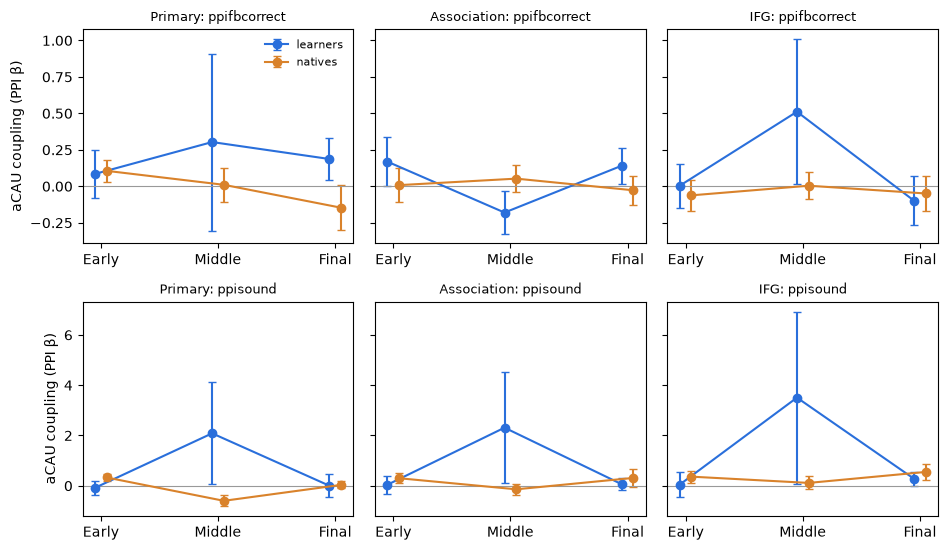

In [12]:
bilat = gs.bilateral_mean(comp)
fig, axes = plt.subplots(2, len(composites), figsize=(3.2 * len(composites), 5.6), sharey='row')
for row, contrast in zip(axes, ['ppifbcorrect', 'ppisound']):
    for ax, region in zip(row, composites):
        sub = bilat[(bilat.contrast == contrast) & (bilat.region == region)]
        for offset, group in zip((-0.05, 0.05), gs.GROUPS):
            stats_ = (sub[sub.participant_group == group].groupby('learning_stage').beta
                      .agg(['mean', 'sem']).reindex(gs.STAGE_ORDER))
            ax.errorbar(np.arange(3) + offset, stats_['mean'], yerr=stats_['sem'], marker='o', capsize=3,
                        color=colors[group], label=labels[group])
        ax.axhline(0, color='0.6', lw=0.8)
        ax.set_xticks(range(3), [s.capitalize() for s in gs.STAGE_ORDER])
        ax.set_title(f'{region}: {contrast}', fontsize=9)
    row[0].set_ylabel('aCAU coupling (PPI β)')
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(out_dir, 'ppi_seed-aCAU_composites_by-stage.png'), dpi=200)

## 9. Save tables

In [13]:
for name, table in {'planned_level': planned_level, 'planned_trend': planned_trend, 'planned_battery': battery,
                    'group_by_stage_anova': anova, 'seed_coupling': seed_coupling,
                    'learners_wrong-and-correct-vs-wrong_trend': learner_trend,
                    'exploratory_region_level': region_level, 'exploratory_region_trend': region_trend}.items():
    table.to_csv(os.path.join(out_dir, f'ppi_seed-aCAU_{name}.tsv'), sep='\t', index=False)
print('saved to', out_dir)

saved to /ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/group_space-T1w_fwhm-0.00/stats_two-group/ppi
